# YOLO v3 Object Detection (browser version)

**Problem.** An *object detector* finds every object in a photo and says what it is and where it is (a box around it). In this notebook we run **YOLO v3** ("You Only Look Once"), a convolutional neural network that does this in a single pass over the image, on two sample photos.

**How to run.** Run the cells from top to bottom (Run → Run All Cells). Everything runs in your browser: the first cell installs one small library, and the pre-trained model (`yolov3-tiny.cfg` and `yolov3-tiny.weights`, about 35 MB), the class names (`coco.names`) and the photos (`dog.jpg`, `person.jpg`) are in the same folder as this notebook. Loading the model takes a few seconds.

**Expected result.** The two photos with coloured boxes, each labelled with a class name and a confidence score: for `dog.jpg` a dog (about 82 %) and the white pick-up, boxed as both a car and a truck; for `person.jpg` a person (about 98 %), the dog (two boxes) and the horse, which this small model calls a sheep. The questions at the end look at these mistakes.

**Why "tiny"?** The original version of this notebook (in *5 Source Files*) builds the full YOLO v3 network in TensorFlow 1 and loads the official 237 MB weights. Neither TensorFlow nor a file that size works in the browser, so here we use **YOLOv3-tiny**, the official smaller version of the same model (about 9 million instead of 62 million parameters), and run it with OpenCV. The ideas (anchors, detection layers, non-max suppression) are the same; the small model is faster but less accurate.

## 1. What is YOLO?
YOLO is an algorithm that uses convolutional neural networks for object detection.
So what's great about object detection? In comparison to recognition (classification) algorithms, a detection algorithm does not only predict class labels, but detects the locations of objects as well.

## 2. Libraries
We need NumPy (numerical computation), OpenCV (`cv2`, which can read and run a pre-trained Darknet/YOLO model) and Pillow (image processing). We also use seaborn's colour palette for the box colours, and the IPython function `display()` to show images in the notebook. Seaborn is not part of the browser's Python, so the next cell installs it.

In [1]:
%pip install seaborn

In [2]:
import io                                     # keeps a photo in memory as JPEG bytes
import numpy as np
import cv2                                    # runs the pre-trained YOLO network (instead of TensorFlow)
from PIL import Image, ImageDraw, ImageFont   # loads photos and draws the boxes
from IPython.display import display, Image as IPImage  # shows images in the notebook
from seaborn import color_palette             # one colour per class

## 3. Configuration
`_MODEL_SIZE` is the input size of the model: every photo is resized to 416 × 416 pixels. `_ANCHORS` are the six anchor boxes of YOLOv3-tiny (they are listed in `yolov3-tiny.cfg`; the full YOLO v3 uses nine).

In [3]:
_MODEL_SIZE = (416, 416)
_ANCHORS = [(10, 14), (23, 27), (37, 58),
            (81, 82), (135, 169), (344, 319)]

### Batch normalization
Almost every convolutional layer in YOLO has batch normalization after it. It helps the model train faster and reduces the variance between units. Each value $x$ in a batch is normalized with the batch mean $\mu$ and variance $\sigma^2$, and then scaled and shifted with two learned parameters $\gamma$ and $\beta$:

$$\hat{x} = \frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}, \qquad y = \gamma\,\hat{x} + \beta$$

$\epsilon$ (`1e-05` in YOLO) avoids division by zero. During training the network also keeps a moving average of the mean and variance, which it uses at inference time (after training) instead of the batch statistics:

`moving_average = momentum * moving_average + (1 - momentum) * current_average` (YOLO uses `momentum = 0.9`).

These values are stored in the weights file, so OpenCV applies them for us.

### Leaky ReLU
Leaky ReLU is a slight modification of the ReLU activation function: $f(x) = x$ for $x > 0$ and $f(x) = \alpha x$ for $x \le 0$, with a small slope $\alpha$ (0.1 in YOLO). The idea is to prevent so-called "dying neurons", which happen when many activations become 0 and stop learning.

### Anchors
Anchors are bounding-box priors that were calculated on the COCO dataset using k-means clustering. The network predicts the width and height of each box as offsets from these anchors, and the centre of the box relative to the grid cell where the filter is applied, using a sigmoid function:

$$b_{x} = \sigma(t_{x})+c_{x}$$
$$b_{y} = \sigma(t_{y})+c_{y}$$
$$b_{w} = p_{w}e^{t_{w}}$$
$$b_{h} = p_{h}e^{t_{h}}$$

where $b_{x}$ and $b_{y}$ are the centre coordinates of the box, $b_{w}$ and $b_{h}$ are its width and height, $c_{x}$ and $c_{y}$ are the position of the grid cell, $p_{w}$ and $p_{h}$ are the anchor width and height, and the $t_{i}$ are the values the network predicts (regression).

## 4. The model
**Feature extraction.** The full YOLO v3 uses *Darknet-53*, a 53-layer network pre-trained on ImageNet with shortcut (residual) connections, like ResNet. YOLOv3-tiny uses a much shorter stack of convolution and max-pooling layers instead.

**Detection layers.** YOLO v3 detects on 3 different scales (YOLOv3-tiny on 2), each with its own anchors. For each cell of the feature map, a detection layer predicts `n_anchors * (5 + n_classes)` values using a 1 × 1 convolution: for each of the 3 anchors of that scale, 4 box coordinates, a confidence score (the probability that the box contains an object) and one probability per class. COCO has 80 classes, so each row of the output has 5 + 80 = 85 values.

**Upsampling.** Before detecting at a finer scale, the feature map is upsampled (nearest-neighbour interpolation) and concatenated with an earlier, more detailed feature map.

The next cell loads the network. OpenCV reads the official Darknet files directly: `yolov3-tiny.cfg` describes the layers and `yolov3-tiny.weights` holds the trained parameters.

In [4]:
net = cv2.dnn.readNetFromDarknet('yolov3-tiny.cfg', 'yolov3-tiny.weights')
output_layers = net.getUnconnectedOutLayersNames()   # the detection ("yolo") layers
print('Detection layers:', output_layers)

Detection layers: ('yolo_16', 'yolo_23')


### Non-max suppression
The model produces a lot of boxes, so we need a way to discard the boxes with low confidence scores. Also, to avoid having several boxes for one object, we discard boxes that overlap a better box too much, using **non-max suppression** for each class.

Overlap is measured with **IoU** (Intersection over Union): the area where two boxes overlap divided by the area they cover together. IoU is 1 for identical boxes and 0 for boxes that don't touch.

The functions below are NumPy versions of the TensorFlow functions in the original notebook: `build_boxes` turns centre/width/height into corner coordinates, and `non_max_suppression` keeps, for each class, the most confident box and removes the boxes that overlap it by more than `iou_threshold`.

In [5]:
def build_boxes(inputs):
    """Computes top left and bottom right points of the boxes."""
    center_x, center_y, width, height = inputs[:, 0], inputs[:, 1], inputs[:, 2], inputs[:, 3]
    confidence, classes = inputs[:, 4:5], inputs[:, 5:]

    top_left_x = center_x - width / 2
    top_left_y = center_y - height / 2
    bottom_right_x = center_x + width / 2
    bottom_right_y = center_y + height / 2

    corners = np.stack([top_left_x, top_left_y, bottom_right_x, bottom_right_y], axis=-1)
    return np.concatenate([corners, confidence, classes], axis=-1)


def iou(box, boxes):
    """Intersection over Union of one box with each of several boxes (corner coordinates)."""
    x0 = np.maximum(box[0], boxes[:, 0])
    y0 = np.maximum(box[1], boxes[:, 1])
    x1 = np.minimum(box[2], boxes[:, 2])
    y1 = np.minimum(box[3], boxes[:, 3])
    intersection = np.clip(x1 - x0, 0, None) * np.clip(y1 - y0, 0, None)
    area = (box[2] - box[0]) * (box[3] - box[1])
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return intersection / (area + areas - intersection)


def non_max_suppression(boxes, n_classes, max_output_size, iou_threshold,
                        confidence_threshold):
    """Performs non-max suppression separately for each class.

    Args:
        boxes: Array of boxes (corners, confidence, class probabilities) for one image.
        n_classes: Number of classes.
        max_output_size: Max number of boxes to be selected for each class.
        iou_threshold: Threshold for the IOU.
        confidence_threshold: Threshold for the confidence score.
    Returns:
        A class-to-boxes dictionary.
    """
    boxes = boxes[boxes[:, 4] > confidence_threshold]          # drop low-confidence boxes
    classes = np.argmax(boxes[:, 5:], axis=-1)                  # most likely class of each box
    boxes_dict = dict()
    for cls in range(n_classes):
        class_boxes = boxes[classes == cls, :5]
        order = np.argsort(-class_boxes[:, 4])                  # most confident first
        keep = []
        while order.size > 0 and len(keep) < max_output_size:
            best = order[0]
            keep.append(best)
            overlap = iou(class_boxes[best], class_boxes[order[1:]])
            order = order[1:][overlap <= iou_threshold]         # remove boxes that overlap the best one
        boxes_dict[cls] = class_boxes[keep]
    return boxes_dict

## 5. Utility functions
These functions load the photos as NumPy arrays, read the class names from the official COCO file and draw the predicted boxes. They are the same as in the original notebook, except that the label size is now measured with `textbbox` (newer versions of Pillow removed `textsize`) and Pillow's built-in font replaces a font file that is not available here. A small helper, `show_image`, shows a photo in the notebook: the browser kernel cannot show a Pillow image passed straight to `display()`, so the photo is first saved as JPEG bytes.

In [6]:
def load_images(img_names, model_size):
    """Loads images in a 4D array.

    Args:
        img_names: A list of images names.
        model_size: The input size of the model.

    Returns:
        A 4D NumPy array.
    """
    imgs = []

    for img_name in img_names:
        img = Image.open(img_name)
        img = img.resize(size=model_size)
        img = np.array(img, dtype=np.float32)
        img = np.expand_dims(img, axis=0)
        imgs.append(img)

    imgs = np.concatenate(imgs)

    return imgs


def load_class_names(file_name):
    """Returns a list of class names read from `file_name`."""
    with open(file_name, 'r') as f:
        class_names = f.read().splitlines()
    return class_names


def show_image(img):
    """Shows a Pillow image in the notebook as a JPEG."""
    buffer = io.BytesIO()
    img.save(buffer, format='JPEG')
    display(IPImage(data=buffer.getvalue(), format='jpeg'))


def draw_boxes(img_names, boxes_dicts, class_names, model_size):
    """Draws detected boxes.

    Args:
        img_names: A list of input images names.
        boxes_dicts: A list of class-to-boxes dictionaries, one per image.
        class_names: A class names list.
        model_size: The input size of the model.

    Returns:
        None.
    """
    colors = ((np.array(color_palette("hls", 80)) * 255)).astype(np.uint8)
    for num, img_name, boxes_dict in zip(range(len(img_names)), img_names,
                                         boxes_dicts):
        img = Image.open(img_name)
        draw = ImageDraw.Draw(img)
        font = ImageFont.load_default(size=(img.size[0] + img.size[1]) // 100)
        # boxes are in model coordinates (416 x 416): scale them back to the photo
        resize_factor = \
            (img.size[0] / model_size[0], img.size[1] / model_size[1])
        for cls in range(len(class_names)):
            boxes = boxes_dict[cls]
            if np.size(boxes) != 0:
                color = colors[cls]
                for box in boxes:
                    xy, confidence = box[:4], box[4]
                    xy = [xy[i] * resize_factor[i % 2] for i in range(4)]
                    x0, y0 = xy[0], xy[1]
                    thickness = (img.size[0] + img.size[1]) // 200
                    for t in np.linspace(0, 1, thickness):
                        xy[0], xy[1] = xy[0] + t, xy[1] + t
                        xy[2], xy[3] = xy[2] - t, xy[3] - t
                        draw.rectangle(xy, outline=tuple(color))
                    text = '{} {:.1f}%'.format(class_names[cls],
                                               confidence * 100)
                    left, top, right, bottom = draw.textbbox((0, 0), text, font=font)
                    text_size = (right - left, bottom - top)
                    draw.rectangle(
                        [x0, y0 - text_size[1], x0 + text_size[0], y0],
                        fill=tuple(color))
                    draw.text((x0, y0 - text_size[1]), text, fill='black',
                              font=font, anchor='lt')

        show_image(img)

## 6. Running the model
### Sample images
Two photos from the Darknet project (the official YOLO code).

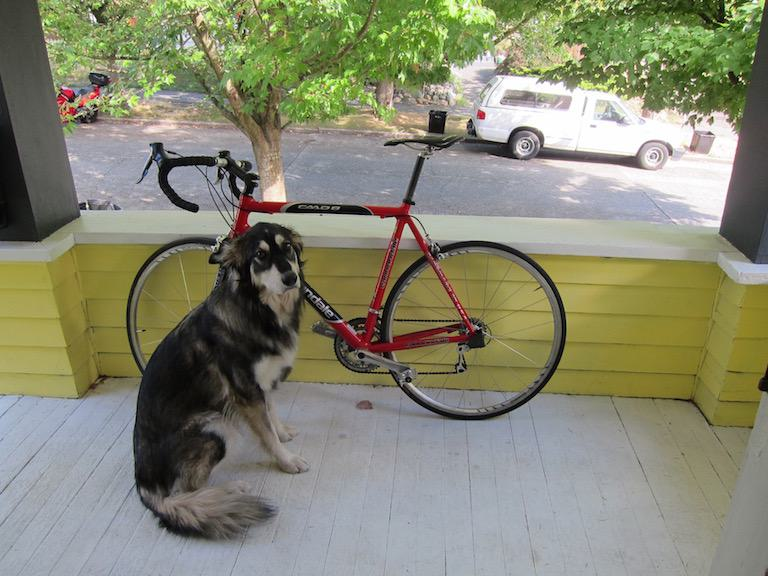

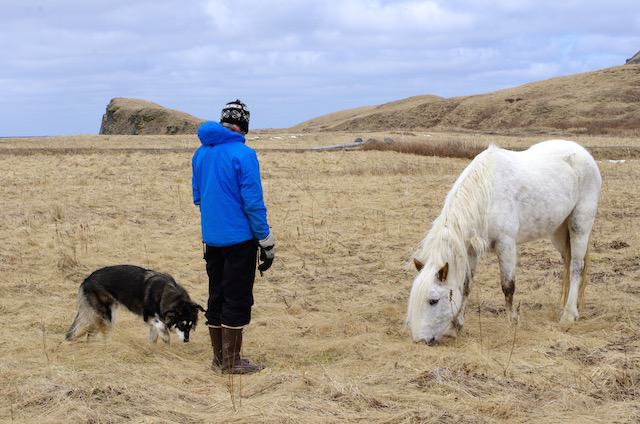

In [7]:
img_names = ['dog.jpg', 'person.jpg']
for img in img_names: show_image(Image.open(img))

### Detections
We test the model with the IoU threshold (used in non-max suppression) and the confidence threshold both set to 0.5, and keep at most 10 boxes per class.

For each photo the cell below:
1. resizes the photo to 416 × 416 and scales the pixel values to 0–1 (`blobFromImage`);
2. runs the network. Each output row is one candidate box: centre x, centre y, width, height (as fractions of the image, already decoded with the anchor formulas above), confidence and 80 class scores;
3. converts the boxes to model pixels and to corner coordinates, and applies non-max suppression;
4. draws the remaining boxes on the photo.

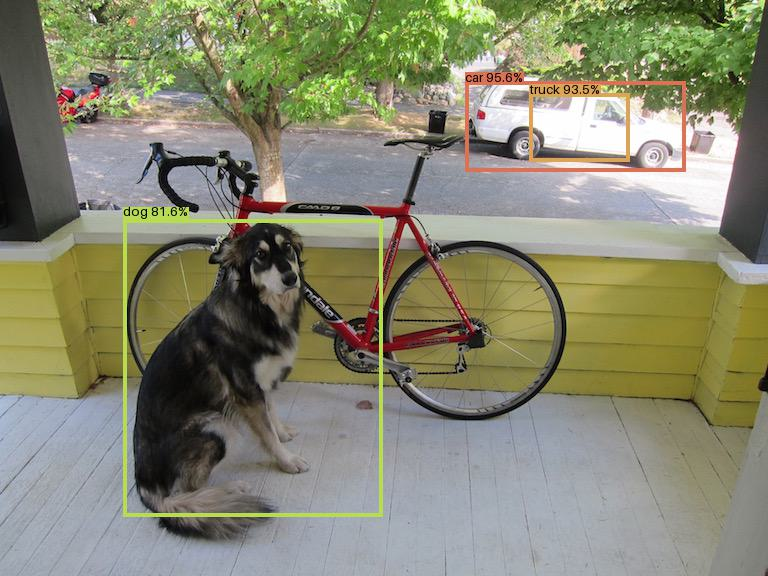

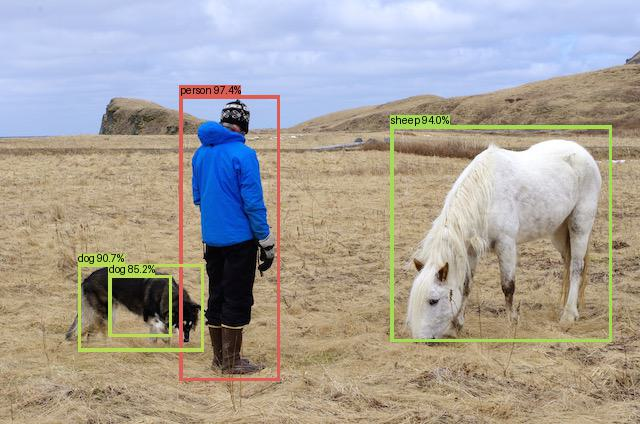

In [8]:
batch = load_images(img_names, model_size=_MODEL_SIZE)
class_names = load_class_names('coco.names')
n_classes = len(class_names)
max_output_size = 10
iou_threshold = 0.5
confidence_threshold = 0.5

detection_result = []
for img in batch:
    # 1. NCHW blob with values 0-1 (the photo is already RGB and 416 x 416)
    blob = cv2.dnn.blobFromImage(img, scalefactor=1 / 255)
    # 2. forward pass: one array of candidate boxes per detection layer
    net.setInput(blob)
    outputs = np.concatenate(net.forward(output_layers))
    # 3. box coordinates from fractions of the image to model pixels, then corners and non-max suppression
    outputs[:, [0, 2]] *= _MODEL_SIZE[0]
    outputs[:, [1, 3]] *= _MODEL_SIZE[1]
    boxes = build_boxes(outputs)
    detection_result.append(non_max_suppression(boxes, n_classes, max_output_size,
                                                 iou_threshold, confidence_threshold))

# 4. draw the boxes
draw_boxes(img_names, detection_result, class_names, _MODEL_SIZE)

## 7. Video processing
The author of the original notebook also applied the same algorithm to a video (*A Street Walk in Shinjuku, Tokyo, Japan*): see the animated result and the code in his [GitHub repository](https://github.com/heartkilla/yolo-v3) (the GIF is about 50 MB, so it is linked rather than shown here).

## What do you notice?
1. Look at the second photo. Which object gets the wrong label, and why might a small model make this mistake?
2. There is a bicycle in the first photo. Is it detected?
3. The white pick-up in the first photo has two boxes, and the dog in the second photo has two boxes. Why doesn't non-max suppression remove one of them?
4. Change `confidence_threshold` to `0.3` in the *Detections* cell and run it again. What happens to the number of boxes?

<details>
<summary>Answers</summary>

1. The horse is labelled **sheep**. YOLOv3-tiny has far fewer layers and parameters than the full YOLO v3, so its features are less detailed, and a white four-legged animal grazing in a field can look like a sheep to it. Accuracy versus speed and size is the main trade-off between the two models.
2. No. The small model is not sure about the thin frame of the bicycle: its best bicycle box has a confidence of only about 32 %, below the threshold of 50 % (the full YOLO v3 finds it with high confidence).
3. Non-max suppression runs separately for each class, so a *car* box and a *truck* box on the same vehicle never compete. The two dog boxes are the same class, but they overlap less than the IoU threshold of 0.5 (one box is much smaller than the other), so both are kept.
4. More boxes appear. In the first photo the bicycle is now found, but there are also extra, less reliable boxes. A lower threshold finds more objects but also gives more false or duplicate detections; 0.5 is a common compromise.
</details>

## Acknowledgements
* [YOLO v3 paper](https://arxiv.org/abs/1804.02767) (Redmon & Farhadi, 2018)
* Original notebook: *Yolo v3 Object Detection in Tensorflow* by the author of [heartkilla/yolo-v3](https://github.com/heartkilla/yolo-v3)
* [A TensorFlow Slim implementation](https://github.com/mystic123/tensorflow-yolo-v3)
* [ResNet official implementation](https://github.com/tensorflow/models/tree/master/official/resnet)
* [DeviceHive video analysis repo](https://github.com/devicehive/devicehive-video-analysis)
* Model files and sample photos: [Darknet](https://github.com/pjreddie/darknet) (public domain)